In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_parquet('processed/df_staging_2.parquet')

In [3]:
#for future model targets scaling
genres_cols = [c for c in df.columns if c.startswith("genres:")]
tags_cols   = [c for c in df.columns if c.startswith("tags:")]
cat_cols    = [c for c in df.columns if c.startswith("categories:")]

# games with no genre at all cant teach the genre model anything
print('games without genres:', (df[genres_cols].sum(axis=1) == 0).sum())
df = df[df[genres_cols].sum(axis=1) > 0].reset_index(drop=True)

games without genres: 8415


In [4]:
# split by column name instead of position, positions break as soon as we add a feature
df_y = df[genres_cols + cat_cols]
df_x = df.drop(columns=genres_cols + cat_cols + tags_cols + ['supported_languages', 'full_audio_languages'])

In [5]:
# counts like reviews / owners / playtime go from 0 to millions
# without log a few huge games dominate the scaling and everything else is squashed near 0
log_cols = ['price', 'positive', 'negative', 'peak_ccu', 'average_playtime_forever', 'median_playtime_forever',
            'average_playtime_2weeks', 'median_playtime_2weeks', 'achievements', 'dlc_count', 'owners_mid', 'n_languages']

df_x[log_cols] = np.log1p(df_x[log_cols].astype('float32').clip(lower=0))
df_x['release_year'] = df_x['release_year'].astype(int)

In [6]:
labels = list(df_y.columns)

In [7]:
df_x_t = pd.get_dummies(
    df_x,
    columns=['release_month','price_status'],
    prefix=['m_','status_']
)

In [8]:
#transforming the data into tensors 

import torch   
df_x_t = df_x_t.astype('float32')
X_t = torch.from_numpy(df_x_t.to_numpy().copy())
print(X_t.shape, X_t.dtype)   # torch.Size([131k, 800]) torch.float32
df_y_t = df_y.astype('float32')
Y_t = torch.from_numpy(df_y_t.to_numpy().copy())
print(Y_t.shape, Y_t.dtype)

torch.Size([131081, 800]) torch.float32
torch.Size([131081, 97]) torch.float32


In [9]:
import numpy as np
import torch
import torch.nn as nn
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
import torchmetrics
from torchmetrics.aggregation import MeanMetric
from copy import deepcopy

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else "cpu") 
torch.manual_seed(42)
np.random.seed(42)
std = StandardScaler()


In [11]:
X_train, X_test, Y_train, Y_test = train_test_split(X_t, Y_t, test_size=0.2, random_state=42)
X_test, X_val, Y_test, Y_val = train_test_split(X_test,Y_test,test_size=0.5,random_state= 42)


# labels with less than 100 games in train are basically noise (accounting, 360 video, web publishing...)
# the model cant learn them and they just drag the mean AP down, so we drop them
keep = (Y_train.sum(0) >= 100).numpy()
print(f'keeping {keep.sum()}/{len(keep)} labels')
Y_train, Y_test, Y_val = Y_train[:, keep], Y_test[:, keep], Y_val[:, keep]
df_y = df_y.loc[:, keep]
genres_cols = [c for c in genres_cols if c in df_y.columns]
cat_cols    = [c for c in cat_cols if c in df_y.columns]

keeping 78/97 labels


In [12]:
X_train,X_test, X_val = std.fit_transform(X_train), std.transform(X_test), std.transform(X_val)

# app.py needs the exact same scaling
joblib.dump(std, 'models/scaler.pkl')

['models/scaler.pkl']

In [13]:

#MODEL CLASS

class GenCatMLP(nn.Module):
    def __init__(self,in_dim,out_dim,hidden = 1024,p=0.5):
        super().__init__()
        def block(ins,outs):
            return nn.Sequential(
                nn.Linear(ins,outs),
                nn.ReLU(),
                nn.Dropout(p),
                

            )
        self.net = nn.Sequential(block(in_dim,hidden),block(hidden,hidden//2),block(hidden//2,hidden//4),nn.Linear(hidden//4, out_dim))

    def forward(self,x):
        return self.net(x)
        


In [14]:
#loss function 
loss_fn = nn.BCEWithLogitsLoss()

In [15]:

#dtype correction 
X_train = torch.from_numpy(X_train).float()
X_val   = torch.from_numpy(X_val).float()
X_test  = torch.from_numpy(X_test).float()

In [15]:
from xgboost import XGBClassifier

modxgb = XGBClassifier()
modxgb.fit(X_train,Y_train, 
           eval_set=[
        (X_train, Y_train),
        (X_test, Y_test)],verbose = 10)

[0]	validation_0-logloss:0.17033	validation_1-logloss:0.17420
[10]	validation_0-logloss:0.12338	validation_1-logloss:0.14560
[20]	validation_0-logloss:0.10717	validation_1-logloss:0.14280
[30]	validation_0-logloss:0.09595	validation_1-logloss:0.14232
[40]	validation_0-logloss:0.08735	validation_1-logloss:0.14269
[50]	validation_0-logloss:0.08021	validation_1-logloss:0.14332
[60]	validation_0-logloss:0.07410	validation_1-logloss:0.14428
[70]	validation_0-logloss:0.06865	validation_1-logloss:0.14523
[80]	validation_0-logloss:0.06399	validation_1-logloss:0.14622
[90]	validation_0-logloss:0.05975	validation_1-logloss:0.14728
[99]	validation_0-logloss:0.05631	validation_1-logloss:0.14825


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [21]:
from torchmetrics.classification import MultilabelAveragePrecision

mlap  = MultilabelAveragePrecision(num_labels=Y_train.shape[1], average="macro")
prob  = torch.tensor(modxgb.predict_proba(X_val), dtype=torch.float32)   # (N, L)
targs = torch.tensor(Y_val, dtype=torch.long)                            # (N, L)
mlap(prob, targs)

C:\Users\Moha\AppData\Local\Temp\ipykernel_13096\3496904119.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  targs = torch.tensor(Y_val, dtype=torch.long)                            # (N, L)


tensor(0.3471)

In [16]:
def train_model(X_train, Y_train, X_val, Y_val, name, epochs=200, patience=15):

    # CONFIG
    train_losses = []
    val_losses = []
    mAP = []  # mean AP over all labels
    best_model_path = f"models/best_{name}.pth"
    tune_model = False
    save_model = False


    # CHECKPOINTS
    model = GenCatMLP(X_train.shape[1], Y_train.shape[1]).to(device)
    if tune_model is True:
        try:
            model.load_state_dict(torch.load(best_model_path, map_location=device))
        except FileNotFoundError:
            print('No best model was found starting from zero')


    # OPTIMIZER
    optim = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-2,
    )


    # METRICS
    train_loss_metric = torchmetrics.aggregation.MeanMetric().to(device)
    val_mAP_metric = torchmetrics.classification.MultilabelAveragePrecision(Y_val.shape[1], average='macro').to(device)
    val_loss_metric = torchmetrics.aggregation.MeanMetric().to(device)

    best_metric = -1.0
    best_epoch = -1


    # DATALOADERS
    train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=2048, shuffle=True)
    val_loader   = DataLoader(TensorDataset(X_val, Y_val),     batch_size=512,  shuffle=False)


    # TRAINING LOOP
    for epoch in range(epochs):

        model.train()
        train_loss_metric.reset()

        for xb, yb in train_loader:

            xb, yb = xb.to(device), yb.to(device)
            optim.zero_grad()

            loss = loss_fn(model(xb), yb)
            train_loss_metric.update(loss.item(), weight=xb.size(0))

            loss.backward()
            optim.step()

        train_losses.append(train_loss_metric.compute().item())

        model.eval()
        val_mAP_metric.reset()
        val_loss_metric.reset()

        with torch.inference_mode():

            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                val_loss_metric.update(loss_fn(logits, yb).item(), weight=xb.size(0))
                val_mAP_metric.update(logits, yb.int())

            mAP.append(val_mAP_metric.compute().item())
            val_losses.append(val_loss_metric.compute().item())

            if mAP[-1] > best_metric:
                best_metric = mAP[-1]
                best_epoch = epoch
                torch.save(deepcopy(model.state_dict()), best_model_path)

        # early stopping, after ~50 epochs it only overfits
        if epoch - best_epoch >= patience:
            print(f'[{name}] no improvement for {patience} epochs, stopping at epoch {epoch}')
            break

        if epoch % 10 == 0:
            print(f'[{name}] Training loss = {train_losses[-1]} validation loss is {val_losses[-1]}, mAP = {mAP[-1]}')
            if best_epoch >= 0:
                print(f'[{name}] best so far: mAP = {best_metric:.4f} epoch {best_epoch} -> {best_model_path}')

    return model, mAP, best_metric, best_model_path, val_losses

In [17]:

#finding out what are the indices for making 2 seperate models 
genres_idx = [df_y.columns.get_loc(c) for c in genres_cols]
cat_idx    = [df_y.columns.get_loc(c) for c in cat_cols]
gencat_idx = genres_idx + cat_idx

# genres only
model_genres, mAP_genres, best_genres, path_genres, val_losses_genres = train_model(
    X_train, Y_train[:, genres_idx],
    X_val,   Y_val[:, genres_idx],
    name='genres'
)

# genres + categories
model_gencat, mAP_gencat, best_gencat, path_gencat, val_losses_gencat = train_model(
    X_train, Y_train[:, gencat_idx],
    X_val,   Y_val[:, gencat_idx],
    name='gencat'
)

[genres] Training loss = 0.2663898169994354 validation loss is 0.1966077983379364, mAP = 0.2900930643081665
[genres] best so far: mAP = 0.2901 epoch 0 -> models/best_genres.pth


[genres] Training loss = 0.16355490684509277 validation loss is 0.1646115928888321, mAP = 0.43277448415756226
[genres] best so far: mAP = 0.4328 epoch 10 -> models/best_genres.pth


[genres] Training loss = 0.15390026569366455 validation loss is 0.1632300615310669, mAP = 0.4674417972564697
[genres] best so far: mAP = 0.4681 epoch 19 -> models/best_genres.pth


[genres] Training loss = 0.1470830738544464 validation loss is 0.16359002888202667, mAP = 0.4800739884376526
[genres] best so far: mAP = 0.4832 epoch 27 -> models/best_genres.pth


[genres] Training loss = 0.14171847701072693 validation loss is 0.16430844366550446, mAP = 0.48724812269210815
[genres] best so far: mAP = 0.4891 epoch 36 -> models/best_genres.pth


[genres] Training loss = 0.13713160157203674 validation loss is 0.16503867506980896, mAP = 0.48682278394699097
[genres] best so far: mAP = 0.4891 epoch 36 -> models/best_genres.pth


[genres] no improvement for 15 epochs, stopping at epoch 51


[gencat] Training loss = 0.2574172914028168 validation loss is 0.18443503975868225, mAP = 0.1669597178697586
[gencat] best so far: mAP = 0.1670 epoch 0 -> models/best_gencat.pth


[gencat] Training loss = 0.14114409685134888 validation loss is 0.13797497749328613, mAP = 0.34205663204193115
[gencat] best so far: mAP = 0.3421 epoch 10 -> models/best_gencat.pth


[gencat] Training loss = 0.13268372416496277 validation loss is 0.13572104275226593, mAP = 0.3548225164413452
[gencat] best so far: mAP = 0.3556 epoch 19 -> models/best_gencat.pth


[gencat] Training loss = 0.1272679716348648 validation loss is 0.1358790099620819, mAP = 0.3632164001464844
[gencat] best so far: mAP = 0.3632 epoch 30 -> models/best_gencat.pth


[gencat] Training loss = 0.12333942949771881 validation loss is 0.13652026653289795, mAP = 0.36930257081985474
[gencat] best so far: mAP = 0.3715 epoch 39 -> models/best_gencat.pth


[gencat] Training loss = 0.12050864845514297 validation loss is 0.13791783154010773, mAP = 0.3714904487133026
[gencat] best so far: mAP = 0.3733 epoch 49 -> models/best_gencat.pth


[gencat] Training loss = 0.11806514114141464 validation loss is 0.13780929148197174, mAP = 0.3765522539615631
[gencat] best so far: mAP = 0.3766 epoch 60 -> models/best_gencat.pth


[gencat] Training loss = 0.11629275232553482 validation loss is 0.1396954208612442, mAP = 0.37642884254455566
[gencat] best so far: mAP = 0.3766 epoch 66 -> models/best_gencat.pth


[gencat] Training loss = 0.11479643732309341 validation loss is 0.1404338926076889, mAP = 0.37546852231025696
[gencat] best so far: mAP = 0.3773 epoch 73 -> models/best_gencat.pth


[gencat] Training loss = 0.11300867795944214 validation loss is 0.14200271666049957, mAP = 0.3790344297885895
[gencat] best so far: mAP = 0.3798 epoch 88 -> models/best_gencat.pth


[gencat] Training loss = 0.11186514049768448 validation loss is 0.1430222988128662, mAP = 0.38173967599868774
[gencat] best so far: mAP = 0.3817 epoch 100 -> models/best_gencat.pth


[gencat] Training loss = 0.11082009971141815 validation loss is 0.14448723196983337, mAP = 0.37765517830848694
[gencat] best so far: mAP = 0.3817 epoch 100 -> models/best_gencat.pth


[gencat] no improvement for 15 epochs, stopping at epoch 115


In [18]:
#data sanity check
pos_counts = Y_train.sum(0)
print(f'labels <10 pos:  {(pos_counts < 10).sum()}')
print(f'labels <30 pos:  {(pos_counts < 30).sum()}')
print(f'labels <100 pos: {(pos_counts < 100).sum()}')

labels <10 pos:  0
labels <30 pos:  0
labels <100 pos: 0


In [19]:
import os
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import average_precision_score

os.makedirs("plots", exist_ok=True)


def eval_model(model, mAP_hist, val_loss_hist, ckpt_path,
               X_test, Y_test, names, tag):
    # load best weights 
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()

    # curves
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(mAP_hist)
    ax[0].set_xlabel('epoch'); ax[0].set_ylabel('mAP')
    ax[0].set_title(f'{tag} mAP')
    ax[0].axhline(max(mAP_hist), color='r', ls='--', alpha=0.5,
                  label=f'best {max(mAP_hist):.3f}')
    ax[0].legend()

    ax[1].plot(val_loss_hist, color='orange')
    ax[1].set_xlabel('epoch'); ax[1].set_ylabel('loss')
    ax[1].set_title(f'{tag} val loss')
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_curves.png', dpi=120)
    plt.show()

    # preds on test
    with torch.inference_mode():
        probs = torch.sigmoid(model(X_test.to(device))).cpu().numpy()
    Yte = Y_test.cpu().numpy()

    ap = average_precision_score(Yte, probs, average=None)
    micro_ap = average_precision_score(Yte, probs, average='micro')

    # "accuracy" a human understands: is the top prediction one of the real labels
    has_label = Yte.sum(1) > 0
    top1_hit = Yte[has_label, probs[has_label].argmax(1)].mean()

    # ap histogram
    plt.figure(figsize=(8, 4))
    plt.hist(ap, bins=20, edgecolor='black')
    plt.axvline(ap.mean(), color='r', ls='--', label=f'mean {ap.mean():.3f}')
    plt.xlabel('AP'); plt.ylabel('count')
    plt.title(f'{tag} per-label AP')
    plt.legend()
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_ap_hist.png', dpi=120)
    plt.show()

    # sorted bars
    order = np.argsort(ap)[::-1]
    plt.figure(figsize=(max(8, len(ap)*0.35), 5))
    plt.bar(range(len(ap)), ap[order])
    plt.xticks(range(len(ap)),
               [names[i].split(':')[-1] for i in order],
               rotation=90, fontsize=7)
    plt.ylabel('AP')
    plt.title(f'{tag} AP per label (sorted)')
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_ap_per_label.png', dpi=120)
    plt.show()

    # preds vs true
    plt.figure(figsize=(8, 4))
    plt.hist(probs.flatten(), bins=50, alpha=0.6, density=True, label='preds')
    plt.hist(Yte.flatten(), bins=50, alpha=0.6, density=True, label='true')
    plt.yscale('log')
    plt.xlabel('value'); plt.ylabel('density')
    plt.title(f'{tag} preds vs true')
    plt.legend()
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_pred_dist.png', dpi=120)
    plt.show()

    print(f'[{tag}] test mAP    : {ap.mean():.4f}')
    print(f'[{tag}] micro AP    : {micro_ap:.4f}')
    print(f'[{tag}] median AP   : {np.median(ap):.4f}')
    print(f'[{tag}] top-1 hit   : {top1_hit:.4f}')
    print(f'[{tag}] best val    : {max(mAP_hist):.4f} (epoch {mAP_hist.index(max(mAP_hist))})')
    print(f'[{tag}] labels >0.5 : {(ap > 0.5).sum()}/{len(ap)}')
    print()

    return ap

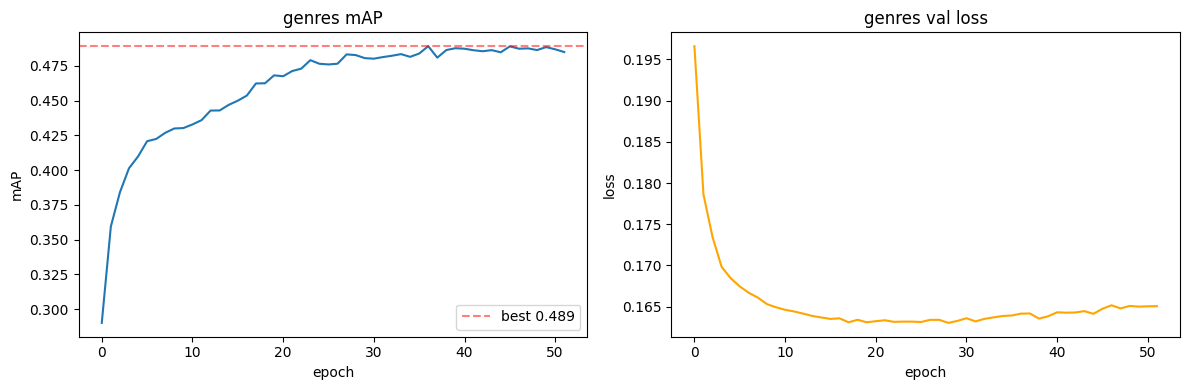

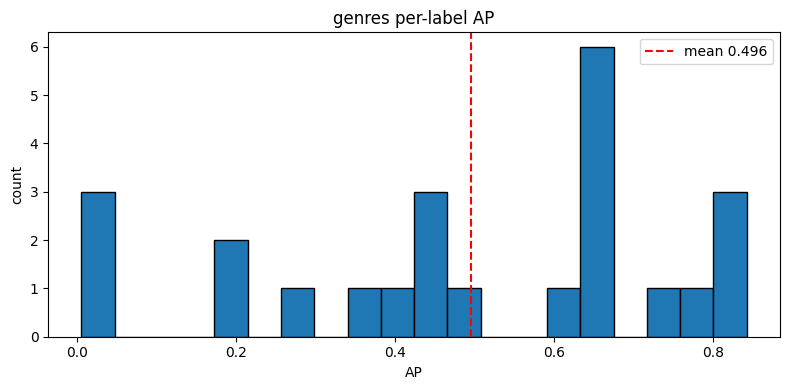

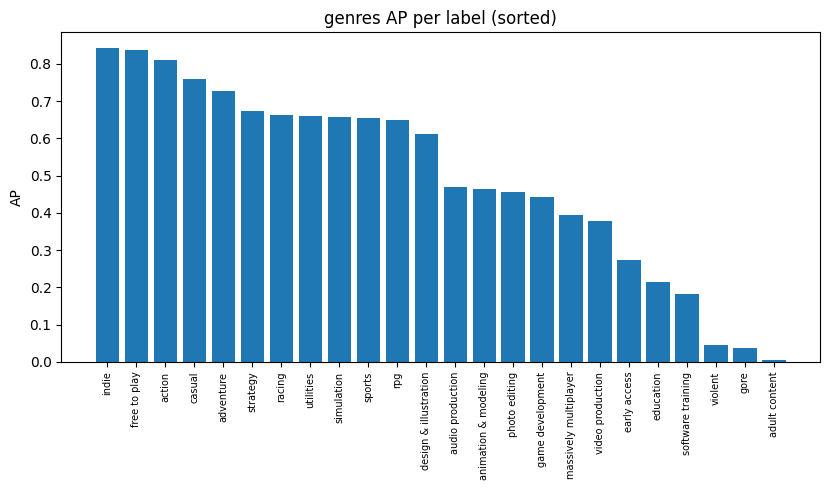

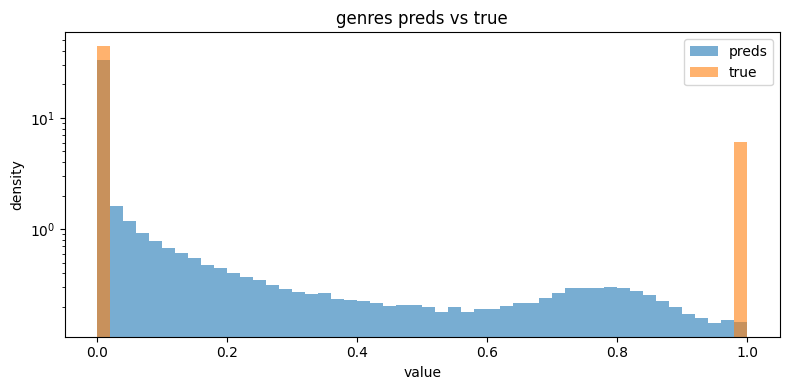

[genres] test mAP    : 0.4962
[genres] micro AP    : 0.7673
[genres] median AP   : 0.5407
[genres] top-1 hit   : 0.8391
[genres] best val    : 0.4891 (epoch 36)
[genres] labels >0.5 : 12/24



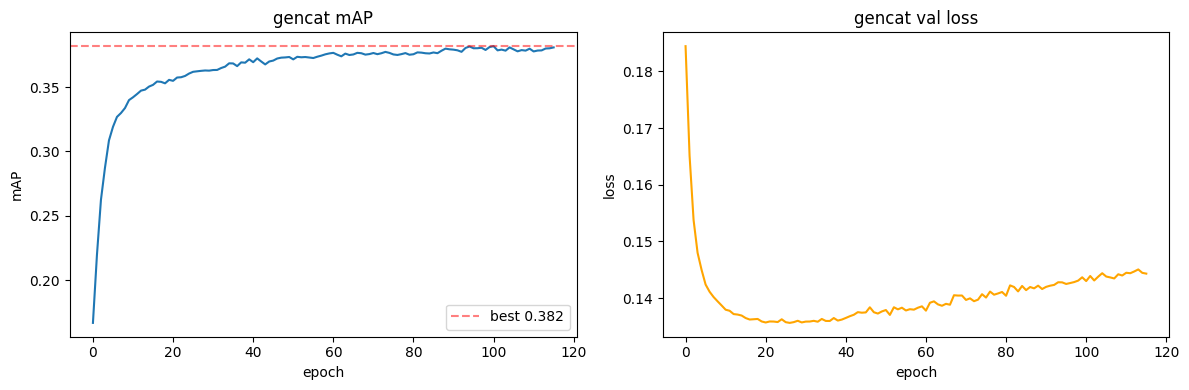

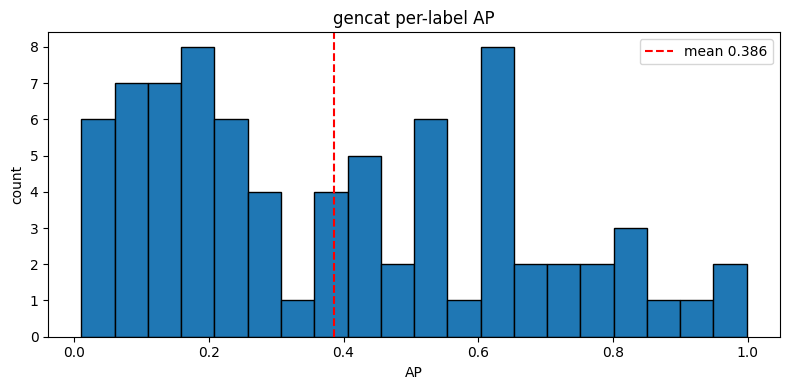

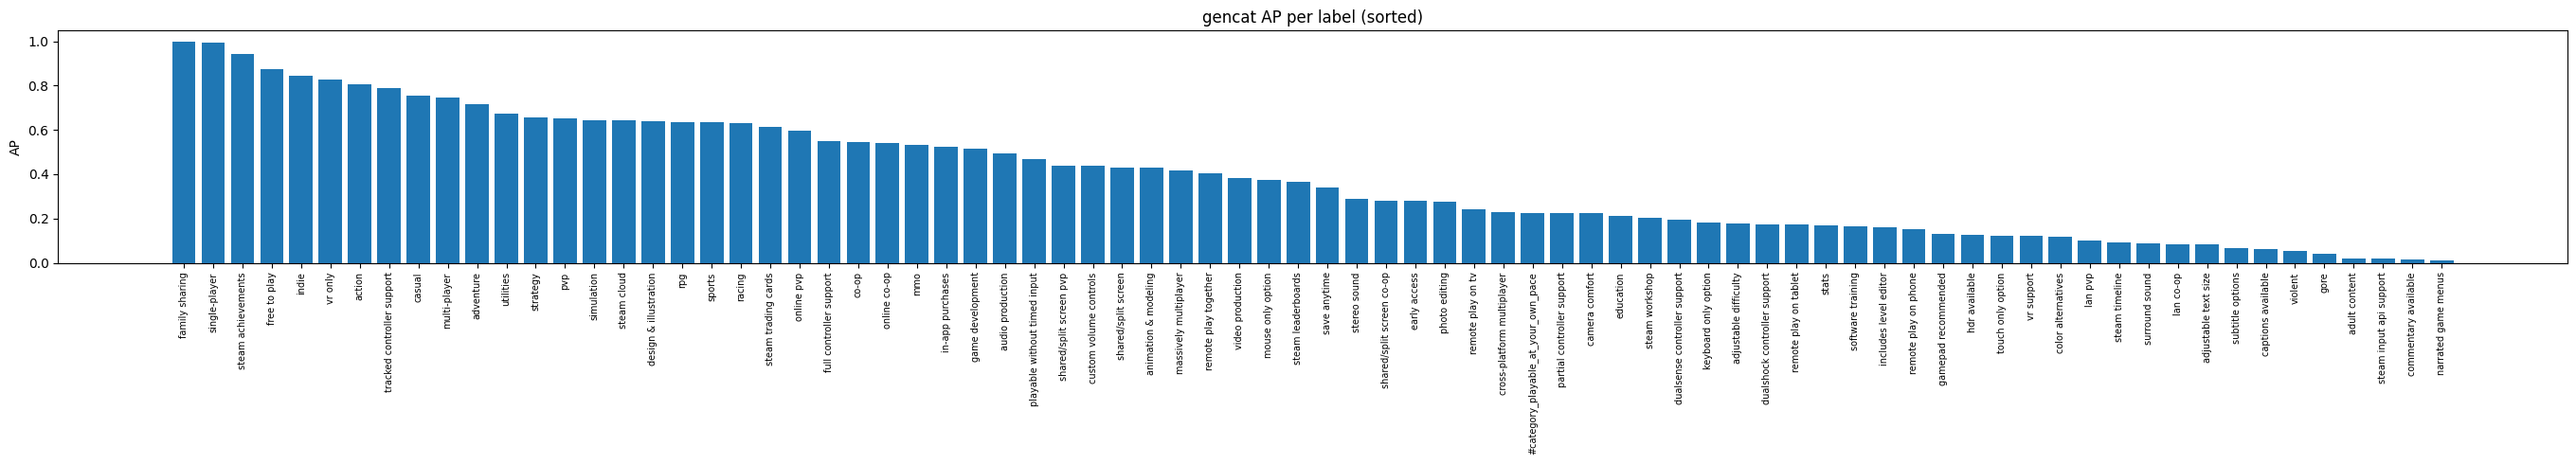

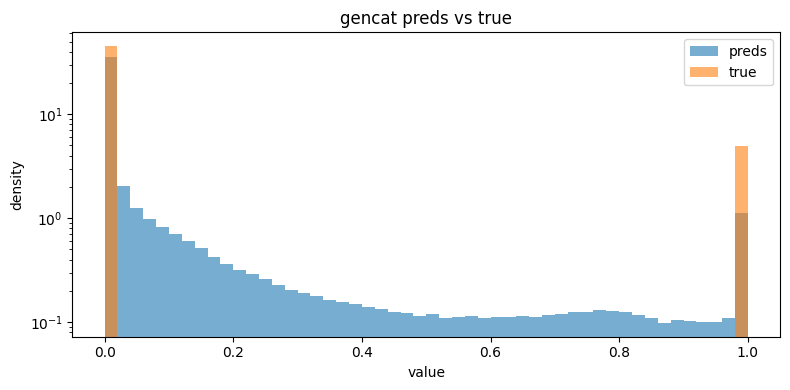

[gencat] test mAP    : 0.3856
[gencat] micro AP    : 0.8055
[gencat] median AP   : 0.3539
[gencat] top-1 hit   : 0.9864
[gencat] best val    : 0.3817 (epoch 100)
[gencat] labels >0.5 : 28/78



In [20]:


#evalutating the models 
genres_names = [df_y.columns[i] for i in genres_idx]
ap_genres = eval_model(model_genres, mAP_genres, val_losses_genres, path_genres,
                       X_test, Y_test[:, genres_idx], genres_names, 'genres')

gencat_names = [df_y.columns[i] for i in gencat_idx]
ap_gencat = eval_model(model_gencat, mAP_gencat, val_losses_gencat, path_gencat,
                       X_test, Y_test[:, gencat_idx], gencat_names, 'gencat')

In [21]:
df_x_t.columns

Index(['emb_0', 'emb_1', 'emb_2', 'emb_3', 'emb_4', 'emb_5', 'emb_6', 'emb_7',
       'emb_8', 'emb_9',
       ...
       'm__06', 'm__07', 'm__08', 'm__09', 'm__10', 'm__11', 'm__12',
       'status__free', 'status__paid', 'status__unavailable'],
      dtype='str', length=800)

In [22]:
#we should save target names for app.py
labels_path = ('labels/')

pd.DataFrame([genres_cols]).to_csv(labels_path + "labels_genres.csv", index=False)
pd.DataFrame([gencat_names]).to_csv(labels_path + "labels_gencat.csv", index=False)





In [23]:
tabular_cols = [c for c in df_x_t.columns if not c.startswith(("emb_", "desc_emb_"))]
pd.Series(tabular_cols).to_csv("labels/feature_columns.csv", index=False, header=False)

In [24]:
tabular_cols

['release_year',
 'price',
 'positive',
 'negative',
 'peak_ccu',
 'metacritic_score',
 'average_playtime_forever',
 'median_playtime_forever',
 'average_playtime_2weeks',
 'median_playtime_2weeks',
 'achievements',
 'dlc_count',
 'windows',
 'mac',
 'linux',
 'owners_mid',
 'n_languages',
 'm__01',
 'm__02',
 'm__03',
 'm__04',
 'm__05',
 'm__06',
 'm__07',
 'm__08',
 'm__09',
 'm__10',
 'm__11',
 'm__12',
 'status__free',
 'status__paid',
 'status__unavailable']